# 15 · Análisis exploratorio: banco temporal, ventana y peso de `BAJA+2`

**Etapa 18 del plan.** El banco del `13` y del `14` no ve el paso del tiempo: entrena y evalúa con los mismos meses, en clientes distintos. Este notebook mide como se trabajaría en producción: para evaluar un mes, entrena solo con meses que ya tienen clase, hasta dos meses antes.

**Preguntas:**
1. Con el tiempo en juego, ¿cuánto suman `ACH` sobre `AC` y `ACH_4` sobre `ACH`?
2. ¿Conviene darle más peso a `BAJA+2` en el entrenamiento?
3. En 201909 y 201910, ¿qué ventana gana más: la de la consigna, todos los meses disponibles o los últimos 4?

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada.

**A diferencia del `13` y del `14`, usa 201909 y 201910.** Por pedido del usuario, se usan como dos meses más para decidir. No carga 201911 ni 201912. **No escribe en `exp/03/` a `exp/14/` ni en los `resultados/03_*` a `14_*`:** solo los lee.

Ficha: `fichas/etapa_18_banco_temporal.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_12 = Path('../exp/12')                          # solo se lee
EXP = Path('../exp/15')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201910                                   # nada posterior entra a este notebook
MESES_TABLA = [201903, 201904, 201905, 201906, 201907, 201908, 201909, 201910]
MESES_EVALUADOS = [201906, 201907, 201908, 201909, 201910]
MESES_FINALES = [201909, 201910]
MESES_CONSIGNA = [201903, 201904, 201905, 201906]
ULTIMOS = 4
DISTANCIA = 2                                       # la clase de un mes se conoce dos meses después
MESES_TRAIN = MESES_CONSIGNA                        # los pide `construir`; acá cada modelo elige su ventana
MESES_EVAL = MESES_FINALES
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]   # como en el 06 y el 12

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
CONFIGS = {                                         # columnas, peso de BAJA+2, ventana, meses evaluados
    'AC':       {'columnas': 'AC',    'peso': 1, 'ventana': 'todos',   'meses': MESES_EVALUADOS},
    'ACH':      {'columnas': 'ACH',   'peso': 1, 'ventana': 'todos',   'meses': MESES_EVALUADOS},
    'ACH_4':    {'columnas': 'ACH_4', 'peso': 1, 'ventana': 'todos',   'meses': MESES_EVALUADOS},
    'ACH_4_P2': {'columnas': 'ACH_4', 'peso': 2, 'ventana': 'todos',   'meses': MESES_EVALUADOS},
    'ACH_4_P3': {'columnas': 'ACH_4', 'peso': 3, 'ventana': 'todos',   'meses': MESES_EVALUADOS},
    'ACH_4_F':  {'columnas': 'ACH_4', 'peso': 1, 'ventana': 'consigna', 'meses': MESES_FINALES},
    'ACH_4_U4': {'columnas': 'ACH_4', 'peso': 1, 'ventana': 'ultimos', 'meses': MESES_FINALES},
}
CONTRASTES = [('ACH', 'AC', MESES_EVALUADOS), ('ACH_4', 'ACH', MESES_EVALUADOS),
              ('ACH_4_P2', 'ACH_4', MESES_EVALUADOS), ('ACH_4_P3', 'ACH_4', MESES_EVALUADOS),
              ('ACH_4_F', 'ACH_4', MESES_FINALES), ('ACH_4_U4', 'ACH_4', MESES_FINALES)]
HIPOTESIS = {
    'AC': 'Referencia: el baseline, con todos los meses disponibles',
    'ACH': 'La historia curada suma también cuando pasa el tiempo',
    'ACH_4': 'Los cuatro bloques del 14 suman también cuando pasa el tiempo',
    'ACH_4_P2': 'Solo BAJA+2 paga: con el doble de peso, el modelo se concentra en esos clientes',
    'ACH_4_P3': 'Lo mismo, con el triple de peso',
    'ACH_4_F': 'La ventana de la consigna, 201903-06: pierde contra todos los meses disponibles',
    'ACH_4_U4': 'Los últimos 4 meses: lo reciente vale más que tener más meses',
}
UMBRAL = 1.0                                        # M por mes, fijado en la ficha
N_INTERCAMBIO = 4_000
FOTOS = 9                                           # 201910 llega hasta 201901

N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_TABLA = (1_037_551, 5_042)                 # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[01234]_*')]
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 37


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` de 201903 a 201910. **Control 2:** nada posterior a 201910 entra al notebook. La clase de 201911 y 201912 nunca se carga.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 2 s


## 3. Tablas

`ACH` y los cuatro bloques se arman con las mismas funciones del `13`, ahora hasta 201910.

| Configuración | Columnas | Peso de `BAJA+2` | Ventana |
|---|---|---:|---|
| `AC` | 760: el baseline | 1 | Todos los meses, hasta dos meses antes del evaluado |
| `ACH` | 880: `AC` + historia curada | 1 | Igual |
| `ACH_4` | 1.180: `ACH` + los cuatro bloques del `14` | 1 | Igual |
| `ACH_4_P2` | Las de `ACH_4` | 2 | Igual |
| `ACH_4_P3` | Las de `ACH_4` | 3 | Igual |
| `ACH_4_F` | Las de `ACH_4` | 1 | 201903–06, la de la consigna. Solo 201909 y 201910 |
| `ACH_4_U4` | Las de `ACH_4` | 1 | Los últimos 4 meses disponibles. Solo 201909 y 201910 |

**Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_TABLA)
assert T['F'].shape == (ESPERADO_TABLA[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_TABLA[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906, 201909):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

Tablas y controles 4 y 6 OK en 23 s · memoria máxima 5.1 GB


## 4. Ventanas y controles

**Control 3:** ningún modelo entrena con un mes posterior a dos meses antes del evaluado.

**Control 5:** `ACH`, entrenada de 201903 a 201907 con la primera semilla y los bins del `12`, da las predicciones del `12` en 201909. Comprueba las filas, las columnas y los hiperparámetros.

**Control 11:** `ACH_4` tiene 1.180 columnas sin nombres repetidos, y las primeras 880 son las de `ACH`.

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}

ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_TABLA}


def meses_de_entrenamiento(config, mes):
    ventana = CONFIGS[config]['ventana']
    if ventana == 'consigna':
        return MESES_CONSIGNA
    disponibles = [m for m in MESES_TABLA if m <= mes - DISTANCIA]
    return disponibles[-ULTIMOS:] if ventana == 'ultimos' else disponibles


def ruta(config, mes, semilla):
    return EXP / 'pred' / config / str(mes) / f'{semilla}.npy'


def tabla_de(columnas, filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    if columnas == CONTROL:
        return T['F'][filas, :ESPERADO_N_VARIABLES[CONTROL]], T['columnas'][:ESPERADO_N_VARIABLES[CONTROL]]
    bloques = CANDIDATAS if columnas == JUNTAS else []
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in bloques])
    return X, T['columnas'][:k] + [c for b in bloques for c in B[b][1]]


# Tareas: una tabla de entrenamiento sirve para varios modelos
TAREAS = {}
for c, e in CONFIGS.items():
    for m in e['meses']:
        entrena = tuple(meses_de_entrenamiento(c, m))
        assert entrena and max(entrena) <= m - DISTANCIA, (c, m, entrena)      # control 3
        TAREAS.setdefault((e['columnas'], entrena), {}).setdefault(c, []).append(m)
print('Tablas de entrenamiento:', len(TAREAS), '· modelos:', sum(len(t) for t in TAREAS.values()) * N_SEMILLAS)
print(pd.DataFrame([{'config': c, **{m: f'{min(meses_de_entrenamiento(c, m)) % 100:02d}-{max(meses_de_entrenamiento(c, m)) % 100:02d}' for m in e['meses']}}
                    for c, e in CONFIGS.items()]).set_index('config').fillna('').to_string())

# Control 11
columnas_juntas = tabla_de(JUNTAS, np.arange(2))[1]
assert len(columnas_juntas) == len(set(columnas_juntas)) == ESPERADO_N_VARIABLES[JUNTAS]
assert columnas_juntas[:ESPERADO_N_VARIABLES[BASE_CURADA]] == T['columnas'][:ESPERADO_N_VARIABLES[BASE_CURADA]]

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    entrena = np.isin(T['mes_fila'], [201903, 201904, 201905, 201906, 201907])
    X, columnas = tabla_de(BASE_CURADA, entrena)
    y = np.isin(CLASE[T['filas'][entrena]], POSITIVOS).astype(np.int8)
    dtrain = lgb.Dataset(X, label=y, feature_name=columnas, params={'max_bin': 31, 'feature_pre_filter': False}, free_raw_data=False)
    modelo = lgb.train({**MEJORES, 'seed': SEMILLAS[0]}, dtrain, num_boost_round=ARBOLES)
    prob = modelo.predict(tabla_de(BASE_CURADA, es_mes[201909])[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_12 / 'pred' / 'ACH_R' / '201909' / f'{SEMILLAS[0]}.npy')), 'ACH no reproduce el 12'
    ruta_control.write_text('ok\n')
    del X, y, dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 3 y 11 OK')

Tablas de entrenamiento: 17 · modelos: 140
         201906 201907 201908 201909 201910
config                                     
AC        03-04  03-05  03-06  03-07  03-08
ACH       03-04  03-05  03-06  03-07  03-08
ACH_4     03-04  03-05  03-06  03-07  03-08
ACH_4_P2  03-04  03-05  03-06  03-07  03-08
ACH_4_P3  03-04  03-05  03-06  03-07  03-08
ACH_4_F                        03-06  03-06
ACH_4_U4                       04-07  05-08
Control 5 OK en 40 s
Controles 3 y 11 OK


## 5. Modelos

Cada tabla de entrenamiento se arma una vez y sirve para todos los modelos que la comparten. Con peso 2 o 3, `BAJA+2` cuenta 2 o 3 veces en la función que optimiza el modelo. `BAJA+1` y `CONTINUA` siguen en 1, y `BAJA+1` sigue siendo positiva.

**Retomar:** cada predicción se guarda al terminar. Los bins usan una semilla fija, para que un modelo dé lo mismo aunque la corrida se corte.

**Control 7:** cada configuración tiene predicción para cada mes y semilla.

In [5]:
falta_de = lambda c, meses, s: [m for m in meses if not ruta(c, m, s).exists()]
pendientes = sum(bool(falta_de(c, meses, s)) for t in TAREAS.values() for c, meses in t.items() for s in SEMILLAS)
print('Modelos pendientes:', pendientes)
segundos = {}
for (columnas_de, entrena_meses), por_config in TAREAS.items():
    if not any(falta_de(c, meses, s) for c, meses in por_config.items() for s in SEMILLAS):
        continue
    entrena = np.isin(T['mes_fila'], entrena_meses)
    X, columnas = tabla_de(columnas_de, entrena)
    clase = CLASE[T['filas'][entrena]]
    dtrain = lgb.Dataset(X, label=np.isin(clase, POSITIVOS).astype(np.int8), feature_name=columnas, params=BINS, free_raw_data=False).construct()
    X_mes = {m: tabla_de(columnas_de, es_mes[m])[0] for meses in por_config.values() for m in meses}
    for config, meses in sorted(por_config.items(), key=lambda kv: CONFIGS[kv[0]]['peso']):
        peso = CONFIGS[config]['peso']
        dtrain.set_weight(np.where(clase == 'BAJA+2', peso, 1).astype(np.float32) if peso > 1 else None)
        for semilla in SEMILLAS:
            if not falta_de(config, meses, semilla):
                continue
            t0 = time.time()
            modelo = lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)
            for m in meses:
                destino = ruta(config, m, semilla)
                assert destino.is_relative_to(EXP), destino
                destino.parent.mkdir(parents=True, exist_ok=True)
                np.save(destino, modelo.predict(X_mes[m], num_threads=N_HILOS).astype(np.float32))
            segundos.setdefault(config, []).append(time.time() - t0)
        print(f'{config} · {entrena_meses[0]} a {entrena_meses[-1]}: {len(columnas)} variables, {np.mean(segundos.get(config, [0])):.0f} s por modelo · memoria máxima {memoria_gb()} GB')
    del X, X_mes, dtrain, clase
    gc.collect()

PUNTAJE = {(c, m): np.stack([np.load(ruta(c, m, s)) for s in SEMILLAS]) for c, e in CONFIGS.items() for m in e['meses']}
assert all(v.shape == (N_SEMILLAS, es_mes[k[1]].sum()) and not np.isnan(v).any() for k, v in PUNTAJE.items())   # control 7
print('Predicciones completas:', len(PUNTAJE), 'grupos de', N_SEMILLAS, 'semillas')

Modelos pendientes: 140
AC · 201903 a 201904: 760 variables, 15 s por modelo · memoria máxima 5.1 GB
AC · 201903 a 201905: 760 variables, 20 s por modelo · memoria máxima 5.1 GB
AC · 201903 a 201906: 760 variables, 24 s por modelo · memoria máxima 5.1 GB
AC · 201903 a 201907: 760 variables, 28 s por modelo · memoria máxima 5.1 GB
AC · 201903 a 201908: 760 variables, 32 s por modelo · memoria máxima 5.1 GB
ACH · 201903 a 201904: 880 variables, 21 s por modelo · memoria máxima 5.1 GB
ACH · 201903 a 201905: 880 variables, 26 s por modelo · memoria máxima 5.1 GB
ACH · 201903 a 201906: 880 variables, 30 s por modelo · memoria máxima 5.1 GB
ACH · 201903 a 201907: 880 variables, 34 s por modelo · memoria máxima 5.1 GB
ACH · 201903 a 201908: 880 variables, 39 s por modelo · memoria máxima 5.1 GB
ACH_4 · 201903 a 201904: 1180 variables, 31 s por modelo · memoria máxima 5.1 GB
ACH_4_P2 · 201903 a 201904: 1180 variables, 32 s por modelo · memoria máxima 5.1 GB
ACH_4_P3 · 201903 a 201904: 1180 var

## 6. Comparaciones

**Medida:** ganancia en la banda de 3.000 a 6.000 envíos, para cada mes y semilla. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla, como en el `14`.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las configuraciones de cada comparación.

El intervalo es la diferencia más o menos 1,96 errores totales.

**Intercambios:** con el ensamble de las 5 semillas y 4.000 envíos, cuántos clientes cambian entre dos configuraciones y cuántos `BAJA+2` entran y salen. Cada `BAJA+2` de diferencia vale 1,1 M.

In [6]:
B_MES = {(c, m): np.array([banda(curva(p, ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[(c, m)]]) for c, m in PUNTAJE}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[(c, m)][i]), 6)}
         for c, m in PUNTAJE for i, s in enumerate(SEMILLAS)]
meses_tabla = pd.DataFrame(filas)
meses_tabla.to_csv(RESULTADOS / '15_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config, lista_meses):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in lista_meses:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[(config, m)]:
            orden = np.argsort(-p, kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(lista_meses) * N_SEMILLAS)


def remuestrear(d, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = len(d)
    con_valor = np.flatnonzero(d)
    salida = np.empty(n_veces)
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ d[con_valor]
    return salida


def por_semilla(config, lista_meses):
    return np.mean([B_MES[(config, m)] for m in lista_meses], axis=0)


def ensamble(config, lista_meses):
    return float(np.mean([banda(curva(PUNTAJE[(config, m)].mean(axis=0), ES_B2[es_mes[m]])) / 1e6 for m in lista_meses]))


filas = []
for j, (c, contra, lista) in enumerate(CONTRASTES):
    d_cliente = por_cliente(c, lista) - por_cliente(contra, lista)
    d = d_cliente.sum() / 1e6
    assert abs(d - (por_semilla(c, lista).mean() - por_semilla(contra, lista).mean())) < 1e-6
    e_c = (remuestrear(d_cliente, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + j) / 1e6).std()
    desvio = np.sqrt((por_semilla(c, lista).var(ddof=1) + por_semilla(contra, lista).var(ddof=1)) / 2)
    e_s = desvio * np.sqrt(2 / N_SEMILLAS)
    e_t = float(np.hypot(e_c, e_s))
    filas.append({'config': c, 'contra': contra, 'meses': len(lista), 'd_M': d, 'error_clientes_M': e_c, 'error_semilla_M': e_s, 'error_total_M': e_t,
                  'ic95_inf_M': d - 1.96 * e_t, 'ic95_sup_M': d + 1.96 * e_t, 'd_ensamble_M': ensamble(c, lista) - ensamble(contra, lista),
                  **{f'd_{m}': B_MES[(c, m)].mean() - B_MES[(contra, m)].mean() for m in lista}})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '15_comparacion.csv', index=False)

filas = []
for c, contra, lista in CONTRASTES:
    for m in lista:
        y = ES_B2[es_mes[m]]
        n = len(y)
        marca = {}
        for k in (c, contra):
            marca[k] = np.zeros(n, dtype=bool)
            marca[k][np.argsort(-PUNTAJE[(k, m)].mean(axis=0), kind='stable')[:N_INTERCAMBIO]] = True
        entran, salen = marca[c] & ~marca[contra], marca[contra] & ~marca[c]
        filas.append({'config': c, 'contra': contra, 'foto_mes': m, 'clientes_que_entran': int(entran.sum()),
                      'baja2_entran': int(y[entran].sum()), 'baja2_salen': int(y[salen].sum()),
                      'd_M': (int(y[entran].sum()) - int(y[salen].sum())) * (GANANCIA_ACIERTO + COSTO_ESTIMULO) / 1e6})
intercambios = pd.DataFrame(filas)
intercambios.to_csv(RESULTADOS / '15_intercambios.csv', index=False)

print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in e['meses']} for c, e in CONFIGS.items()}).T.round(2).to_string())
print()
print('AUC por mes (media de semillas):')
print(meses_tabla.groupby(['config', 'foto_mes'])['auc'].mean().unstack().loc[list(CONFIGS)].round(4).to_string())
print()
print('Intercambios con 4.000 envíos (ensamble):')
print(intercambios.groupby(['config', 'contra'], sort=False)[['clientes_que_entran', 'baja2_entran', 'baja2_salen', 'd_M']].sum().round(1).to_string())

EXPLORATORIO
  config contra  meses   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d_ensamble_M  d_201906  d_201907  d_201908  d_201909  d_201910
     ACH     AC      5  4.09              1.39             0.71           1.56        1.03        7.15          4.38      7.52      3.06      3.47      4.04      2.35
   ACH_4    ACH      5  1.61              1.06             0.74           1.29       -0.92        4.13          1.16     -1.20      0.13      1.90      2.88      4.31
ACH_4_P2  ACH_4      5  0.94              0.76             0.65           1.00       -1.01        2.89          1.50      2.41      0.57      3.12     -0.41     -0.99
ACH_4_P3  ACH_4      5  1.10              0.94             0.63           1.13       -1.12        3.33          1.22      2.18     -0.09      3.00      0.05      0.37
 ACH_4_F  ACH_4      2 -5.79              1.63             0.82           1.82       -9.36       -2.23         -4.88       NaN       NaN       NaN     -

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

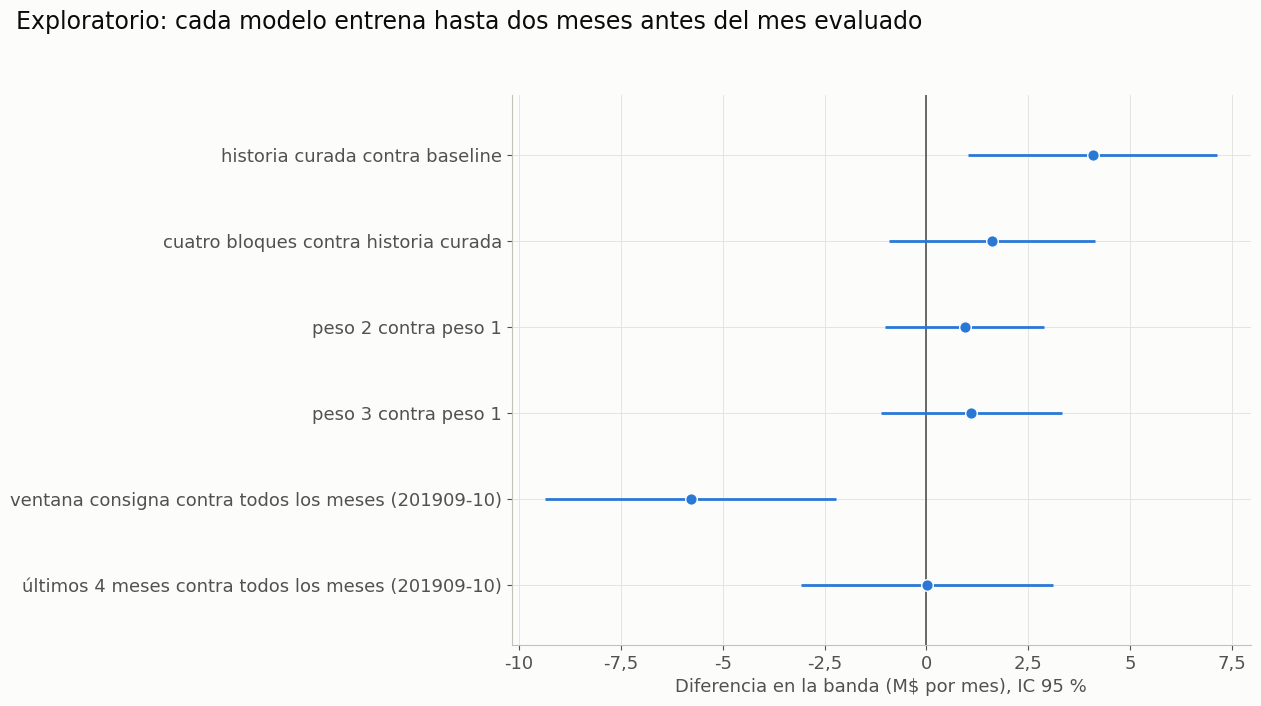

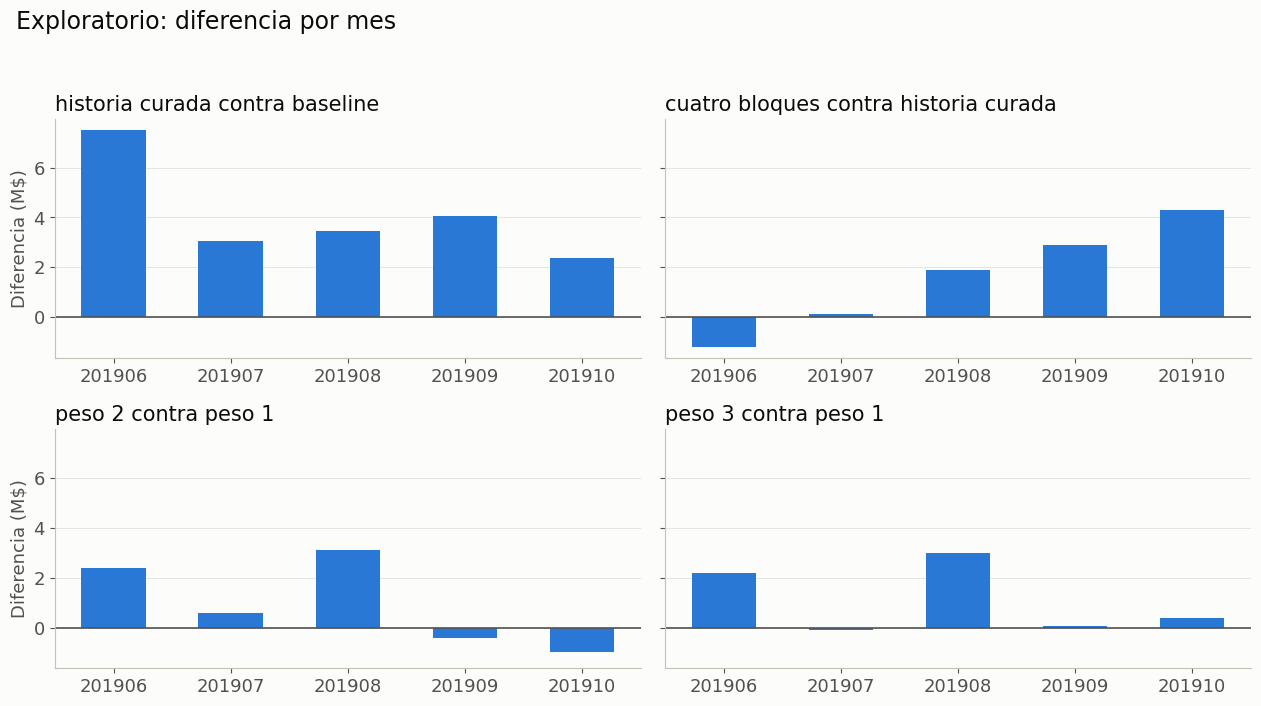

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


NOMBRES = {'ACH': 'historia curada contra baseline', 'ACH_4': 'cuatro bloques contra historia curada', 'ACH_4_P2': 'peso 2 contra peso 1',
           'ACH_4_P3': 'peso 3 contra peso 1', 'ACH_4_F': 'ventana consigna contra todos los meses (201909-10)',
           'ACH_4_U4': 'últimos 4 meses contra todos los meses (201909-10)'}
t = comparacion.set_index('config')
orden = [c for c, _, _ in CONTRASTES]
y = np.arange(len(orden))[::-1]
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ax = plt.subplots(figsize=TAMANO)
ax.axvline(0, color=TINTA_2, lw=1.2)
ax.hlines(y, t.loc[orden, 'ic95_inf_M'], t.loc[orden, 'ic95_sup_M'], color=AZUL, lw=2)
ax.scatter(t.loc[orden, 'd_M'], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
ax.set_yticks(y, [NOMBRES[c] for c in orden])
ax.set_ylim(-0.7, len(orden) - 0.3)
ax.xaxis.set_major_formatter(formato)
ax.set_xlabel('Diferencia en la banda (M$ por mes), IC 95 %')
fig.suptitle('Exploratorio: cada modelo entrena hasta dos meses antes del mes evaluado', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '15_1_banco_temporal.png', dpi=DPI)
plt.show()

cuatro = orden[:4]
fig, ejes = plt.subplots(2, 2, figsize=TAMANO, sharey=True)
for ax, c in zip(ejes.ravel(), cuatro):
    valores = [t.loc[c, f'd_{m}'] for m in MESES_EVALUADOS]
    ax.axhline(0, color=TINTA_2, lw=1.2)
    ax.bar([str(m) for m in MESES_EVALUADOS], valores, color=AZUL, width=0.55)
    ax.yaxis.set_major_formatter(formato)
    ax.set_title(NOMBRES[c], loc='left')
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(True)
for ax in ejes[:, 0]:
    ax.set_ylabel('Diferencia (M$)')
fig.suptitle('Exploratorio: diferencia por mes', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '15_2_por_mes.png', dpi=DPI)
plt.show()

## 8. Lecturas fijadas antes de correr

Para cada comparación, con `d` = la diferencia media en la banda:

| `d` | Lectura |
|---|---|
| +1 M o más | Suma: se adopta |
| Entre −1 y +1 M | Empate: queda lo más simple |
| −1 M o menos | Resta: se descarta |

El intervalo se informa siempre, pero no decide: elegimos por ganancia esperada.

**Control 8:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

lectura = lambda d: 'Suma' if d >= UMBRAL else ('Resta' if d <= -UMBRAL else 'Empate')
for r in comparacion.itertuples():
    print(f'{r.config} contra {r.contra}, {r.meses} meses: {r.d_M:+.2f} M ({r.ic95_inf_M:.2f} a {r.ic95_sup_M:.2f}) · error {r.error_total_M:.2f} M · ensamble {r.d_ensamble_M:+.2f} M · {lectura(r.d_M)}')
print()
promedio = {c: por_semilla(c, MESES_FINALES).mean() for c in CONFIGS}
print('Ganancia media en 201909 y 201910 (M):', {c: round(v, 2) for c, v in sorted(promedio.items(), key=lambda kv: -kv[1])})

iteraciones = pd.DataFrame([{
    'config': c, 'hipotesis': HIPOTESIS[c], 'ganancia_banda_201909_10_M': round(promedio[c], 3),
    'contra': comparacion.set_index('config').contra.get(c, ''),
    'd_M': round(comparacion.set_index('config').d_M.get(c, np.nan), 3),
    'resultado': lectura(comparacion.set_index('config').d_M[c]) if c in set(comparacion.config) else 'base',
} for c in CONFIGS])
iteraciones.to_csv(RESULTADOS / '15_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 117.3 min en total · memoria máxima 5.4 GB
Segundos por modelo: {'AC': 31.9, 'ACH': 39.3, 'ACH_4': 56.1, 'ACH_4_P2': 56.5, 'ACH_4_P3': 55.6, 'ACH_4_F': 54.8, 'ACH_4_U4': 56.0}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

ACH contra AC, 5 meses: +4.09 M (1.03 a 7.15) · error 1.56 M · ensamble +4.38 M · Suma
ACH_4 contra ACH, 5 meses: +1.61 M (-0.92 a 4.13) · error 1.29 M · ensamble +1.16 M · Suma
ACH_4_P2 contra ACH_4, 5 meses: +0.94 M (-1.01 a 2.89) · error 1.00 M · ensamble +1.50 M · Empate
ACH_4_P3 contra ACH_4, 5 meses: +1.10 M (-1.12 a 3.33) · error 1.13 M · ensamble +1.22 M · Suma
ACH_4_F contra ACH_4, 2 meses: -5.79 M (-9.36 a -2.23) · error 1.82 M · ensamble -4.88 M · Resta
ACH_4_U4 contra ACH_4, 2 meses: +0.02 M (-3.07 a 3.11) · error 1.58 M · ensamble +0.89 M · Empate

Ganancia media en 201909 y 201910 (M): {'ACH_4_P3': np.float64(276.49), 'ACH_4_U4': np.float64(276.29), 'ACH_4': np.float64(276.27), 'ACH_4_P2': np.float64(275.58), 